# Eval — assess prompt grounding on held-out reviews

Scores the `assess` prompt (the 5-line analyst report) on **real held-out customer
reviews** (option 2), on **all five lines and on its extractive lines 1–3** (option 3),
under a judge that is **not the generator model** (D7). Every result goes to a new
per-run directory under `data/eval/runs/` (D9) and a new MLflow run (D10).

Design: [`mini_design-analyst_prompt_scoring.md`](../docs/part_1/mini_design-analyst_prompt_scoring.md) ·
Plan: [`implement_plan_[analyst_prompt_scoring].md`](../docs/part_1/implement_plan_[analyst_prompt_scoring].md).
The query-based harness this was copied from is [`eval_qa_grounding.ipynb`](eval_qa_grounding.ipynb),
left untouched.

# Set up

In [1]:
!dir

 Volume in drive K is Kao
 Volume Serial Number is 3C88-5590

 Directory of k:\Gen AI\project\retail_rag\notebook

10/26/2026  05:33 PM    <DIR>          .
10/20/2026  01:42 PM    <DIR>          ..
10/12/2026  02:24 PM            53,827 data_server_info.ipynb
10/12/2026  02:21 PM           330,003 eda_wongnai_reviews.ipynb
10/26/2026  04:15 PM            74,216 eval_assess_grounding.ipynb
10/26/2026  04:06 PM           148,857 eval_assess_grounding.run-N10.ipynb
10/27/2026  10:29 AM            76,830 eval_assess_grounding.run-N100.ipynb
10/20/2026  10:34 AM           164,181 eval_qa_grounding.ipynb
10/12/2026  02:22 PM            37,752 rag.ipynb
02/16/2026  10:29 PM           156,983 rag.png
               8 File(s)      1,042,649 bytes
               2 Dir(s)  90,284,679,168 bytes free


In [2]:
cd ..

k:\Gen AI\project\retail_rag


## Run sheet — read this before running anything

**Every cell from the run-config cell onward spends money on your OpenAI key.**
Cells are named by the first comment line they carry (`# ---- run config ----` and so on).
Services: `docker compose up -d` (Milvus) and `mlflow server --host 127.0.0.1 --port 5000`.
**Do not run k6 at the same time** — it shares the key, and 429s come back as 500s.

| Step | Do | Stop if |
|---|---|---|
| **R1** preflight | Check `N_MAX = 100` and `SWEEP_STEP = 20` in the **run config** cell, then run every cell down to and including it. It pings the judge **before** it creates `OUT_DIR` | It raises `judge … unreachable` → D7 fallback: set `JUDGE_MODEL = "gpt-5-nano"`, add the self-grading caveat to `run_meta.json` (record-the-run cell), re-run. Never call those scores independently judged |
| **R2** self-retrieval | In a terminal: `python scripts/sample_heldout_reviews.py --check-retrieval` | Any id at ≥ 0.99 → stop; have that row replaced (not re-seeded), then restart at R1 |
| **R4** sweep N = 20, 40 … 100, ~$4.05 | Continue R1's kernel. Run the **generation** cell, then the **D4 count** cell — then **stop and read the count** (table below) | See below. Budget guard fires → completed points are kept; `TOP_K = 3`, or raise `BUDGET_USD` deliberately and record why |

**R4 — the D4 count, read before any judging:**

| You see | Do |
|---|---|
| `90/100` or more usable | Run the remaining cells |
| fewer than `90/100` usable | **Stop before judging.** Read `dropped.json` in `OUT_DIR`; a Thai-aware slice becomes a blocker |
| `0/100` usable, or an `AssertionError` on iteration 1 | Generation did not run under `assess` — a notebook bug. Stop |

**After the run, read its output:** `cost.json` actual vs. the projection the sweep cell printed
(> 2× → reasoning tokens the projection cannot see; budget the next run from the actual); `sweep.csv` has
`faithfulness_full` and `faithfulness_extractive` and **no** `faithfulness`;
`run_meta.json` has `self_retrieval_ids: []` and a `sentiment_mix`.

**Rules**

- **Never re-run the run-config cell mid-run.** It mints a new `RUN_SLUG` and a new
  `OUT_DIR` (`exist_ok=False`), and the earlier directory is left empty or half-filled.
  Restart the kernel instead, and delete the orphaned directory by hand.
- After every run, the two fixed files must be byte-identical (`git status` cannot see them):
  `cd data/eval && sha256sum rag_responses.jsonl thai_queries.jsonl` →
  `9778f58c…7ef6` and `1b81ba31…e732`.

# 1.) Grounding — RAGAS on held-out reviews

Two LLM-judged metrics, on opposite sides of the pipeline:

| Metric | Judges | Fails when |
|---|---|---|
| **Context precision** | Retriever | top-5 is padded with reviews that merely share vocabulary |
| **Faithfulness** | Generator | the report asserts what the sources never said |

Neither needs a ground-truth answer. `LLMContextPrecisionWithoutReference` judges
each chunk against the *generated* report, so the two metrics are not independent,
and this does **not** retire the labelled Phase 6 set.

### The eval set

100 real reviews from [`data/eval/reviews_heldout_sample.jsonl`](../data/eval/reviews_heldout_sample.jsonl),
sampled from the corpus's **never-ingested** `test_file.csv` split with a pinned
seed (D5). Each review is the `question` — it fills the `assess` prompt's
`<review>` slot, exactly as an operator would submit it — and the retriever finds
similar past reviews for `Precedent`. Context precision is therefore re-measured
on review-shaped inputs (D6): quote it as a new figure, never next to the
query-based 0.795 as if comparable.

### The sweep: N = 20, 40 … 100

The query-based harness this notebook was copied from,
[`eval_qa_grounding.ipynb`](eval_qa_grounding.ipynb), swept N = 10, 20 … 100, re-judging the first N **from
scratch** at every point — 550 judged rows, ~2.8× the cap with this judge (C5).
Here the sweep steps by `SWEEP_STEP = 20` up to `N_MAX = 100`: 20 + 40 + 60 + 80 + 100 =
**300** judged rows, ~$4.05, in one run with one `RUN_SLUG`.

### If the kernel restarts

Generations are written to `OUT_DIR/responses.jsonl` the moment generation
finishes, before any judging. To judge them without paying to regenerate, run the
run-config cell (a **new** run directory), then this instead of the generation cell:

```python
import shutil
PREVIOUS = Path("data/eval/runs/<RUN_SLUG of the interrupted run>")
RESUMED_FROM = PREVIOUS.name
shutil.copy(PREVIOUS / "responses.jsonl", OUT_DIR)     # same name, this run's directory
records = [
    {k: r[k] for k in ("id", "user_input", "response", "retrieved_contexts", "top1_score")}
    for r in (json.loads(line) for line
              in (PREVIOUS / "responses.jsonl").read_text(encoding="utf-8").splitlines()
              if line.strip())
][:N_MAX]
generation_cost = embedding_cost = 0.0      # paid in PREVIOUS -- see its cost.json
sweep_frames = {}
```

### The budget guard

Hard cap of **$4.50** (~150.30 THB). Cost is projected *before* each batch; if the
projection would cross the cap the batch is skipped and everything already paid
for is kept. Each judge pass also records its **actual** token usage
(ragas's OpenAI usage parser), and the ledger is charged whichever of projected and
actual is larger.

The judge is **gpt-5.4-nano** ($0.20/1M in, $1.25/1M out) — a different model
from the `gpt-5-nano` generator, so the scores are not self-graded (D7). OpenAI's
model page marks it **Deprecated** (checked 2026-10-19): record the date beside
any score.

> **The judge runs at `temperature=1`**, not 0. ragas hardcodes `0.01` and
> writes it onto the client before every call; `gpt-5-*` reject anything but the
> default with a 400, and ragas catches those per job — so the run completes and
> returns **NaN for every score**. `PinnedTempChatOpenAI` in the sweep cell drops
> the parameter from the request payload so the API never sees it. The cost is
> that verdicts vary slightly between runs.

> **Projections count visible tokens only.** Both models are reasoning models, and
> reasoning tokens are billed as output — the most likely reason actual spend
> exceeds the projection. This run's `cost.json` is where that gets measured.

Requires `pip install "ragas==0.4.3" langchain-openai`. Pin it — the judge
prompts ship with the library, so an unpinned upgrade moves the scores on its own.

In [4]:
# Preflight. Two things worth checking before spending money:
#
# 1. ragas is mid-migration -- the metric classes moved to
#    ragas.metrics.collections, and the flat ragas.metrics imports used below
#    are deprecated in 0.4 / removed in 1.0. Field names changed in 0.2 too.
# 2. mlflow is optional. Its absence only disables the logging cells at the end;
#    the evaluation itself does not touch it.
import importlib.metadata as md

REQUIRED = {
    "ragas": 'pip install "ragas==0.4.3"',
    "langchain-openai": "pip install langchain-openai",
    "langchain-core": "(installed with langchain-openai)",
}
OPTIONAL = {
    "mlflow": "pip install mlflow   # only for the logging cells at the end",
    "boto3": "pip install boto3     # only for MLflow *artifacts* -- see the MLflow cell",
}

for group, packages in [("required", REQUIRED), ("optional", OPTIONAL)]:
    print(f"-- {group} --")
    for package, hint in packages.items():
        try:
            print(f"  {package:18} {md.version(package)}")
        except md.PackageNotFoundError:
            print(f"  {package:18} NOT INSTALLED  ->  {hint}")


-- required --
  ragas              0.4.3
  langchain-openai   1.5.0
  langchain-core     1.5.4
-- optional --
  mlflow             3.13.0
  boto3              1.43.73


In [5]:
# ---- run config ----
# Never re-run this cell mid-run: it mints a new RUN_SLUG and a new OUT_DIR.
import hashlib
import json
import subprocess
import time
from datetime import datetime, timezone
from pathlib import Path

import tiktoken
from openai import OpenAI

from app.config import settings
from app.services.prompts import PROMPT_SETS
from app.services.rag_service import answer_query
from evaluation.extractive import extractive_only, sentiment_label
from evaluation.heldout import SAMPLE_SEED

# ---------------------------------------------------------------- budget ----
BUDGET_USD = 4.50           # hard cap, ~150.30 THB -- the step-20 sweep projects ~$4.05

# Independent of settings.llm_model (D7): a model grading its own output is a
# weaker check than a different judge.
#
# gpt-5-* accept only the default temperature=1, while ragas hardcodes 0.01 and
# writes it onto the client before every call. See PinnedTempChatOpenAI in the
# sweep cell for how that is neutralised.
JUDGE_MODEL = "gpt-5.4-nano"

# USD per 1M tokens. Verified against developers.openai.com/api/docs/pricing
# on 2026-08-13 -- re-check before trusting a cost estimate, these move.
PRICING = {
    "gpt-5-nano":            {"in": 0.05, "cached_in": 0.005, "out": 0.40},
    "gpt-5-mini":            {"in": 0.25, "cached_in": 0.025, "out": 2.00},
    "gpt-4o":                {"in": 2.50, "cached_in": 1.25,  "out": 10.00},
    "gpt-4o-mini":           {"in": 0.15, "cached_in": 0.075, "out": 0.60},
    "text-embedding-3-small": {"in": 0.02, "cached_in": 0.0,  "out": 0.0},
    # Confirmed 2026-10-19 from OpenAI's model page -- screenshots/gpt-5.4-nano_price.png.
    # The page marks the model Deprecated: record the date beside any score (Risk 18).
    "gpt-5.4-nano":          {"in": 0.20, "cached_in": 0.02,  "out": 1.25},
}


def cost_usd(model: str, tokens_in: int = 0, tokens_out: int = 0,
             cached_in: int = 0) -> float:
    """USD for a call. Input dominates in RAG -- chunks dwarf the question."""
    rate = PRICING[model]
    return (tokens_in / 1e6 * rate["in"]
            + cached_in / 1e6 * rate["cached_in"]
            + tokens_out / 1e6 * rate["out"])


_encoding = tiktoken.get_encoding("cl100k_base")

def ntokens(text: str) -> int:
    """Approximate token count. cl100k is not gpt-5's tokenizer, but it is the
    right order of magnitude and Thai text tokenizes heavily either way."""
    return len(_encoding.encode(text))


class Budget:
    """Running spend against a hard cap.

    `can_afford` is asked *before* each batch so the cap is never exceeded --
    a batch that would cross it is skipped, and everything already paid for
    is kept.
    """

    def __init__(self, limit_usd: float):
        self.limit = limit_usd
        self.spent = 0.0
        self.ledger = []

    def charge(self, label: str, usd: float) -> float:
        self.spent += usd
        self.ledger.append({"label": label, "usd": usd, "cumulative": self.spent})
        return self.spent

    def can_afford(self, usd: float) -> bool:
        return self.spent + usd <= self.limit

    @property
    def remaining(self) -> float:
        return max(0.0, self.limit - self.spent)

    def __repr__(self) -> str:
        pct = 100 * self.spent / self.limit if self.limit else 0
        return (f"${self.spent:.4f} / ${self.limit:.2f} ({pct:.1f}%)  "
                f"remaining ${self.remaining:.4f}")


# -- G1: is the judge reachable on this key? ------------------------------------
# One call (< $0.0001) BEFORE any directory is created or any money committed.
# The old harness recorded gpt-5-nano as the only model its key could reach
# (design Risk 5). Runs before OUT_DIR.mkdir so a 403 leaves nothing behind.
try:
    OpenAI(api_key=settings.openai_api_key).chat.completions.create(
        model=JUDGE_MODEL, messages=[{"role": "user", "content": "ping"}])
except Exception as exc:
    raise RuntimeError(
        f"judge {JUDGE_MODEL} unreachable ({type(exc).__name__}: {exc}). D7 fallback: "
        "set JUDGE_MODEL = 'gpt-5-nano', state the self-grading caveat in run_meta.json, "
        "and do not describe the scores as independently judged."
    ) from exc
print(f"judge       {JUDGE_MODEL} reachable")

# --------------------------------------------------------------- eval set ----
EVAL_SET = "reviews_heldout"
EVAL_FILE = Path("data/eval/reviews_heldout_sample.jsonl")
PROMPT_SET = "assess"
TOP_K = 5

# Sweep N = 20, 40 ... 100 in one run. The sweep re-judges records[:n] from
# scratch at every point, so steps of 20 judge 300 rows (steps of 10: 550) (C5).
# N_MAX must be a multiple of SWEEP_STEP, or the last point misses it.
N_MAX = 100
SWEEP_STEP = 20
SWEEP_POINTS = list(range(SWEEP_STEP, N_MAX + 1, SWEEP_STEP))   # [20, 40, 60, 80, 100]
assert SWEEP_POINTS[-1] == N_MAX, f"N_MAX={N_MAX} is not a multiple of SWEEP_STEP={SWEEP_STEP}"

# Order is significant: N_MAX takes the first N by id (data/eval/README.md).
eval_rows = sorted(
    (json.loads(line) for line
     in EVAL_FILE.read_text(encoding="utf-8").splitlines() if line.strip()),
    key=lambda r: r["id"],
)[:N_MAX]

EVAL_SET_SHA = hashlib.sha256(EVAL_FILE.read_bytes()).hexdigest()[:12]
GIT_SHA = subprocess.run(["git", "rev-parse", "--short", "HEAD"],
                         capture_output=True, text=True).stdout.strip()
TS = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M")
RUN_SLUG = f"assess-{EVAL_SET}-N{N_MAX}-step{SWEEP_STEP}-{JUDGE_MODEL}-{TS}"
OUT_DIR = Path("data/eval/runs") / RUN_SLUG
OUT_DIR.mkdir(parents=True, exist_ok=False)     # never reuse a directory (D9)

budget = Budget(BUDGET_USD)
print(f"run         {RUN_SLUG}")
print(f"eval set    {len(eval_rows)} rows from {EVAL_FILE} (sha {EVAL_SET_SHA}, seed {SAMPLE_SEED})")
print(f"budget      {budget}")
print(f"judge       {JUDGE_MODEL}  "
      f"(in ${PRICING[JUDGE_MODEL]['in']}/1M, out ${PRICING[JUDGE_MODEL]['out']}/1M)")
print(f"generator   {settings.llm_model}  via {settings.llm_provider}, prompt {PROMPT_SET}")
print(f"sweep       N = {SWEEP_POINTS}")

DASHSCOPE_API_KEY not set. Qwen service will fail on generate_answer().


judge       gpt-5.4-nano reachable
run         assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358
eval set    100 rows from data\eval\reviews_heldout_sample.jsonl (sha a023765acc0a, seed 20261019)
budget      $0.0000 / $4.50 (0.0%)  remaining $4.5000
judge       gpt-5.4-nano  (in $0.2/1M, out $1.25/1M)
generator   gpt-5-nano  via openai, prompt assess
sweep       N = [20, 40, 60, 80, 100]


In [7]:
# ---- generation ----
import pandas as pd

# Generate one assess report per held-out review, once, up front. The sweep then
# slices this list, so generation is paid for once instead of once per point.
#
# Generation is charged per review *as it goes*, and the loop stops the moment
# the next answer would breach the cap. The guard has to live here too: with
# long Thai contexts, generation alone can exhaust the budget before the sweep
# ever starts, and a warning printed after the money is spent is not a guard.
#
# GENERATION_SHARE caps generation only -- the judge guard checks the whole
# BUDGET_USD minus what is already spent (C6).
GENERATION_SHARE = 0.60

# What the generator sees besides the review and the chunks: the assess system
# prompt and the user template around them.
PROMPT_OVERHEAD = (ntokens(PROMPT_SETS[PROMPT_SET].system)
                   + ntokens(PROMPT_SETS[PROMPT_SET].user_template))

# ragas field names (renamed in 0.2): user_input / response / retrieved_contexts.
# `id` and `top1_score` ride along for D4's dropped ids and the self-retrieval
# check; the sweep strips them before handing rows to ragas.
records = []
generation_cost = 0.0
embedding_cost = 0.0        # review embeddings, one per search
generation_cap = budget.limit * GENERATION_SHARE
started = time.perf_counter()

for i, row in enumerate(eval_rows, 1):
    text = row["text"]
    result = answer_query(text, top_k=TOP_K, prompt=PROMPT_SET)

    # C2: without prompt= this resolves to settings.prompt_set ("default", QA
    # prose), and D4's count would read 0/N only AFTER all N were paid for.
    # Checked on the first answer: one generation (~$0.0002) instead of N.
    if i == 1:
        assert result["prompt_set"] == PROMPT_SET, (
            f"generated under {result['prompt_set']!r}, not {PROMPT_SET!r} -- stop (C2)")

    contexts = [doc["text"] for doc in result["sources"]]
    # IP over normalized embeddings: ~1.0 means the review is already indexed
    # and retrieved itself (D5). Free here -- the search already ran.
    top1_score = result["sources"][0]["score"] if result["sources"] else None

    tokens_in = ntokens(" ".join(contexts)) + ntokens(text) + PROMPT_OVERHEAD
    tokens_out = ntokens(result["answer"])
    this_call = cost_usd(settings.llm_model, tokens_in, tokens_out)

    # Every review is also embedded once before the vector search -- at ~525
    # tokens a review, no longer the rounding error a short query was.
    this_embed = cost_usd(settings.embedding_model, tokens_in=ntokens(text))
    embedding_cost += this_embed

    generation_cost += this_call
    records.append({
        "id": row["id"],
        "user_input": text,
        "response": result["answer"],
        "retrieved_contexts": contexts,
        "top1_score": top1_score,
    })

    if i % 10 == 0 or i == len(eval_rows):
        print(f"  {i:3}/{len(eval_rows)}  ${generation_cost:.4f}")

    # Stop before the *next* answer if it would eat the generation allowance.
    if (generation_cost + embedding_cost + this_call + this_embed
            > generation_cap and i < len(eval_rows)):
        print(f"\n!! generation stopped at {i}/{len(eval_rows)} reviews: "
              f"${generation_cost:.4f} of the ${generation_cap:.2f} allowance "
              f"({GENERATION_SHARE:.0%} of the ${budget.limit:.2f} cap)")
        print(f"   the sweep will run over the {len(records)} answers generated")
        break

budget.charge("generation", generation_cost)
budget.charge("review embeddings", embedding_cost)
sweep_frames = {}          # N -> per-review frame, filled by the sweep below

# ------------------------------------------------------- persist immediately --
# Written the moment generation finishes, before any judging, so a kernel
# restart cannot discard what was just paid for (see the resume snippet above).
#
# E1 / C1: the run's OWN directory. The harness this was copied from wrote to
# the fixed rag_responses.jsonl beside the eval sets -- the 100-row asset this run must never
# touch, and which git cannot recover because it is untracked.
#
# Written to a temp file and then replaced, so an interrupt mid-write cannot
# leave a truncated file where a complete one used to be.
RESPONSE_FILE = OUT_DIR / "responses.jsonl"

_tmp = RESPONSE_FILE.with_suffix(".jsonl.tmp")
with _tmp.open("w", encoding="utf-8") as fh:
    for row, record in zip(eval_rows, records):
        fh.write(json.dumps({
            "id": record["id"],
            "review_id": row["review_id"],
            "source": row["source"],
            "user_input": record["user_input"],
            "response": record["response"],
            "response_extractive": extractive_only(record["response"]),
            "retrieved_contexts": record["retrieved_contexts"],
            "prompt_set": PROMPT_SET,
            "top1_score": record["top1_score"],
            "generator_model": settings.llm_model,
            "top_k": TOP_K,
            "collection": f"{settings.milvus_database}/{settings.milvus_collection}",
        }, ensure_ascii=False) + "\n")
_tmp.replace(RESPONSE_FILE)

print(f"saved       {len(records)} responses -> {RESPONSE_FILE} "
      f"({RESPONSE_FILE.stat().st_size / 1024:.0f} KB)")

print(f"\n{len(records)} answers in {time.perf_counter() - started:.1f}s")
print(f"generation   ${generation_cost:.4f}  ({settings.llm_model}, projected)")
print(f"embeddings   ${embedding_cost:.4f}  ({settings.embedding_model}, projected)")
print(f"budget       {budget}")

top1 = [r["top1_score"] for r in records if r["top1_score"] is not None]
if top1:
    print(f"top-1 score  max {max(top1):.4f}"
          + ("  !! a review retrieved itself -- see run_meta.json" if max(top1) >= 0.99 else ""))

   10/100  $0.0040
   20/100  $0.0085
   30/100  $0.0113
   40/100  $0.0151
   50/100  $0.0197
   60/100  $0.0247
   70/100  $0.0294
   80/100  $0.0332
   90/100  $0.0365
  100/100  $0.0403
saved       100 responses -> data\eval\runs\assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358\responses.jsonl (1739 KB)

100 answers in 2089.4s
generation   $0.0403  (gpt-5-nano, projected)
embeddings   $0.0009  (text-embedding-3-small, projected)
budget       $0.0411 / $4.50 (0.9%)  remaining $4.4589
top-1 score  max 0.7779


# 2.) The extractive slice — scoring the analyst report where it claims to be grounded

The `assess` prompt returns five lines, and **lines 4–5 are prescriptive**: a
recommended action cannot be *entailed* by a source, because sources describe
what happened and these state what should be done. Over the 100 query-based
responses they were **55.5% of generated text**, which caps faithfulness at
**~0.45** no matter how well-grounded lines 1–3 are.

So the same reports are judged twice, under **two names that are never merged**:

| Metric | Scored on | Contexts | Denominator |
|---|---|---|---|
| `faithfulness_full` | All 5 lines | the retrieved past reviews | N |
| `faithfulness_extractive` | Lines 1–3 | **the review itself + the retrieved past reviews** | `n_extractive` — see the count below |

The review is prepended to the extractive pass's contexts because the generator
genuinely saw it in the `<review>` slot, and Sentiment and Issues describe it
(D2). Unlike the query-based harness, that slot now holds a real review, so
option 2 is fully applied.

Two things make these **non-comparable to each other**, and they must be quoted
with their scope or not at all:

1. **Different denominators.** Reports whose line labels are not in English slice
   to nothing and are **dropped and named**, not scored 0 (D4).
2. **Different contexts.** The extractive pass sees one more document.

**R4: stop after the next cell and read its count before running the judge.**

In [9]:
# ---- D4 count ----
# extractive_only is imported in the run-config cell from evaluation/extractive.py
# -- the module T1-T11 pin, and whose regex the k6 load test mirrors (T10).
# Lines 1-3 (Sentiment, Issues, Precedent) are kept; Actions and Priority dropped.

# ------------------------------------------------- count BEFORE judging ----
# A filter with a count, not an assert: an assert dies on the first
# Thai-labelled row with generation already paid for. Dropping rows and naming
# them is the honest form of the same guard; silently scoring them 0 would read
# as a grounding failure rather than a formatting one.
sliced = [(r, extractive_only(r["response"])) for r in records]
dropped = [r for r, s in sliced if not s.strip()]

print(f"extractive slice: {len(sliced) - len(dropped)}/{len(sliced)} usable, "
      f"{len(dropped)} dropped")
if dropped:
    # EXTRACTIVE is English-keyed, so reports emitting Thai line labels slice
    # to nothing (Risk 3). On the query set this was 2/100 (ids 67, 86).
    print("  dropped ids:", [r["id"] for r in dropped])
    print("  (English-keyed slice vs. Thai line labels -- Risk 3)")

# Written now, not at the end: R4 stops HERE when too many rows drop, and the
# dropped reports are what has to be read next.
(OUT_DIR / "dropped.json").write_text(json.dumps(
    [{"id": r["id"], "reason": "extractive slice empty -- no English line labels",
      "response": r["response"]}
     for r in dropped], ensure_ascii=False, indent=2), encoding="utf-8")

records_extractive = [
    {
        "id": r["id"],
        "user_input": r["user_input"],
        "response": s,
        # retrieved_contexts means everything the generator was grounded on, not
        # everything Milvus returned -- the generator genuinely saw the review in
        # the <review> slot, and lines 1-2 describe it (D2, diagnosis 6.2).
        "retrieved_contexts": [r["user_input"]] + r["retrieved_contexts"],
    }
    for r, s in sliced
    if s.strip()
]

print(f"\n{len(records_extractive)} records for the extractive pass "
      f"(vs {len(records)} for the full pass -- different denominators)")
print(f"dropped.json -> {OUT_DIR / 'dropped.json'}")

extractive slice: 97/100 usable, 3 dropped
  dropped ids: [2, 16, 61]
  (English-keyed slice vs. Thai line labels -- Risk 3)

97 records for the extractive pass (vs 100 for the full pass -- different denominators)
dropped.json -> data\eval\runs\assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358\dropped.json


In [10]:
# ---- judge ----
from langchain_openai import ChatOpenAI
from ragas import EvaluationDataset, evaluate
from ragas.cost import get_token_usage_for_openai
from ragas.llms import LangchainLLMWrapper
from ragas.metrics import Faithfulness, LLMContextPrecisionWithoutReference

class PinnedTempChatOpenAI(ChatOpenAI):
    """A ChatOpenAI that never sends `temperature` to the API.

    ragas hardcodes temperature=0.01 and assigns it onto the client before every
    call (LangchainLLMWrapper.generate_text), so whatever ChatOpenAI was built
    with is discarded. gpt-5-* accept only the default temperature=1 and reject
    anything else with a 400 -- and ragas catches those per job, so the run
    completes normally and every score comes back NaN. That failure is silent
    and costs a full sweep to discover.

    Overriding the attribute does not help (pydantic writes through it), so the
    parameter is dropped from the request payload instead: ragas can set the
    attribute all it likes, the API never sees it.
    """

    def _get_request_payload(self, *args, **kwargs):
        payload = super()._get_request_payload(*args, **kwargs)
        payload.pop("temperature", None)
        return payload


# Judge passed explicitly: these scores grade the judge as much as the pipeline,
# so an unrecorded judge makes them unreadable later. Note the judge runs at the
# model default (temperature=1) rather than 0 -- gpt-5-* allow nothing else, so
# verdicts will vary slightly between runs. Record the run id when comparing.
judge = LangchainLLMWrapper(
    PinnedTempChatOpenAI(model=JUDGE_MODEL, api_key=settings.openai_api_key)
)

# ragas re-sends the context once per extracted claim (faithfulness) and once
# per retrieved chunk (context precision). 6x is a deliberate over-estimate:
# the guard must never let an under-estimate breach the cap, so it errs toward
# stopping early rather than overspending.
JUDGE_PASSES = 6
JUDGE_OUT_TOKENS = 250          # per review, both metrics, short verdicts

# n_extractive_count is a denominator, not a score. score_columns_of()
# detects by dtype, so without this it lands on the sweep chart as an axis.
INPUT_COLUMNS = {"user_input", "response", "retrieved_contexts", "reference",
                 "n_extractive_count"}
RAGAS_KEYS = ("user_input", "response", "retrieved_contexts")


def estimate_judge_cost(batch: list[dict]) -> float:
    """Projected judge spend for a batch, computed *before* running it."""
    tokens_in = sum(
        ntokens(" ".join(r["retrieved_contexts"]))
        + ntokens(r["response"]) + ntokens(r["user_input"])
        for r in batch
    )
    return cost_usd(JUDGE_MODEL,
                    tokens_in=tokens_in * JUDGE_PASSES,
                    tokens_out=JUDGE_OUT_TOKENS * len(batch))


def as_dataset(batch: list[dict]) -> EvaluationDataset:
    """Only the fields ragas reads -- id and top1_score stay in `records`."""
    return EvaluationDataset.from_list([{k: r[k] for k in RAGAS_KEYS} for r in batch])


def actual_usage(result) -> dict:
    """Judge tokens and USD as OpenAI reported them (C8).

    completion_tokens includes reasoning tokens, so this is the figure the
    visible-token projection cannot see. None when no usage came back.
    """
    try:
        usage = result.total_tokens()
    except Exception as exc:
        print(f"       !! no token usage: {type(exc).__name__}")
        return {"tokens_in": None, "tokens_out": None, "usd": None}
    usages = usage if isinstance(usage, list) else [usage]
    tokens_in = sum(u.input_tokens for u in usages)
    tokens_out = sum(u.output_tokens for u in usages)
    if not tokens_in and not tokens_out:
        return {"tokens_in": None, "tokens_out": None, "usd": None}
    return {"tokens_in": tokens_in, "tokens_out": tokens_out,
            "usd": cost_usd(JUDGE_MODEL, tokens_in, tokens_out)}


def score_columns_of(frame) -> list[str]:
    """Score columns are named after the metric classes and have been renamed
    across ragas releases -- detect them instead of hardcoding."""
    return [c for c in frame.columns
            if c not in INPUT_COLUMNS and pd.api.types.is_numeric_dtype(frame[c])]


# ------------------------------------------------------------- the sweep ----
# SWEEP_POINTS, step SWEEP_STEP (C5). If generation stopped early, judge what exists.
sweep_points = sorted({min(n, len(records)) for n in SWEEP_POINTS if records})
sweep_results = []
judge_cost = []             # per point and pass: projected vs actual -> cost.json
stopped_at = None

print(f"sweep N = {sweep_points}")
print(f"start {budget}\n")

for n in sweep_points:
    projected = estimate_judge_cost(records[:n])

    if not budget.can_afford(projected):
        stopped_at = n
        print(f"\n!! STOP before N={n}")
        print(f"   projected ${projected:.4f} would reach "
              f"${budget.spent + projected:.4f}, over the ${budget.limit:.2f} cap")
        print(f"   completed N = {[r['n'] for r in sweep_results]}")
        break

    print(f"N={n:3}  projected ${projected:.4f}  running ${budget.spent:.4f}")
    started = time.perf_counter()

    # The full pass: all 5 lines against the retrieved chunks. Its faithfulness
    # is renamed faithfulness_full below -- never plain `faithfulness`, because a
    # 0.09 and a 0.7 under one name across runs is unreadable later (D3).
    result = evaluate(
        dataset=as_dataset(records[:n]),
        metrics=[LLMContextPrecisionWithoutReference(), Faithfulness()],
        llm=judge,
        token_usage_parser=get_token_usage_for_openai,
    )
    elapsed = time.perf_counter() - started

    # Charge the larger of projected and actual: the projection misses reasoning
    # tokens, and the guard must never run on an under-count.
    actual = actual_usage(result)
    charged = max(projected, actual["usd"] or 0.0)
    budget.charge(f"judge N={n}", charged)
    judge_cost.append({"n": n, "pass": "full", "projected_usd": projected,
                       "actual_usd": actual["usd"],
                       "actual_tokens": {"in": actual["tokens_in"], "out": actual["tokens_out"]}})
    print(f"       full pass actual "
          + (f"${actual['usd']:.4f} ({actual['tokens_in']:,} in / {actual['tokens_out']:,} out)"
             if actual["usd"] is not None else "not reported"))

    frame = result.to_pandas()
    sweep_frames[n] = frame

    row = {"n": n, "seconds": elapsed, "cost_usd": charged,
           "cumulative_usd": budget.spent}
    for c in score_columns_of(frame):
        # Scope goes in the name. `faithfulness` alone would collide with the
        # extractive pass below, which is a different metric over a different
        # denominator (D3).
        name = "faithfulness_full" if c == "faithfulness" else c
        row[name] = frame[c].mean()
        row[f"{name}__std"] = frame[c].std()
    # ---------------------------------------------- the extractive pass ----
    # Judged separately, under a distinct name. Faithfulness only -- context
    # precision is unchanged by slicing the response, so re-paying for it would
    # buy nothing. The extractive batch carries a LONGER context (the review is
    # prepended, 6 documents not 5), so the saving is smaller than the shorter
    # response implies.
    batch_extractive = [r for r in records_extractive if r["id"] in
                        {rec["id"] for rec in records[:n]}]
    projected_extractive = estimate_judge_cost(batch_extractive)

    if batch_extractive and budget.can_afford(projected_extractive):
        result_extractive = evaluate(
            dataset=as_dataset(batch_extractive),
            metrics=[Faithfulness()],
            llm=judge,
            token_usage_parser=get_token_usage_for_openai,
        )
        actual_x = actual_usage(result_extractive)
        charged_x = max(projected_extractive, actual_x["usd"] or 0.0)
        budget.charge(f"judge extractive N={n}", charged_x)
        judge_cost.append({"n": n, "pass": "extractive",
                           "projected_usd": projected_extractive,
                           "actual_usd": actual_x["usd"],
                           "actual_tokens": {"in": actual_x["tokens_in"],
                                             "out": actual_x["tokens_out"]}})
        row["cost_usd"] += charged_x
        row["cumulative_usd"] = budget.spent

        extractive_frame = result_extractive.to_pandas()
        row["faithfulness_extractive"] = extractive_frame["faithfulness"].mean()
        row["faithfulness_extractive__std"] = extractive_frame["faithfulness"].std()
        row["n_extractive_count"] = len(batch_extractive)
        print(f"       faithfulness_extractive="
              f"{row['faithfulness_extractive']:.3f} "
              f"(n={len(batch_extractive)}, scope: lines 1-3 + review)  actual "
              + (f"${actual_x['usd']:.4f}" if actual_x["usd"] is not None else "not reported"))
    else:
        print(f"       extractive pass skipped -- projected "
              f"${projected_extractive:.4f} does not fit the remaining budget")

    sweep_results.append(row)

    scores_text = "  ".join(
        f'{"faithfulness_full" if c == "faithfulness" else c}='
        f'{row["faithfulness_full" if c == "faithfulness" else c]:.3f}'
        for c in score_columns_of(frame)
    )
    print(f"       {scores_text}   {elapsed:.1f}s")

sweep = pd.DataFrame(sweep_results)
print(f"final  {budget}")
if stopped_at:
    print(f"stopped before N={stopped_at} -- {len(sweep)} of "
          f"{len(sweep_points)} points completed")

k:\Gen AI\project\retail_rag\retail_rag_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Kao\AppData\Local\Temp\ipykernel_15424\3194556007.py:6: DeprecationWarning: Importing Faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import Faithfulness
  from ragas.metrics import Faithfulness, LLMContextPrecisionWithoutReference
C:\Users\Kao\AppData\Local\Temp\ipykernel_15424\3194556007.py:6: DeprecationWarning: Importing LLMContextPrecisionWithoutReference from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import LLMContextPrecisionWithoutReference
  from ragas.metrics import Faithfulness, LLMCon

sweep N = [20, 40, 60, 80, 100]
start $0.0411 / $4.50 (0.9%)  remaining $4.4589

N= 20  projected $0.1483  running $0.0411


Evaluating:  30%|███       | 12/40 [03:09<06:26, 13.80s/it]Exception raised in Job[0]: TimeoutError()
Exception raised in Job[10]: TimeoutError()
Exception raised in Job[4]: TimeoutError()
Exception raised in Job[12]: TimeoutError()
Exception raised in Job[14]: TimeoutError()
Evaluating:  68%|██████▊   | 27/40 [04:20<01:14,  5.73s/it]Exception raised in Job[20]: TimeoutError()
Exception raised in Job[18]: TimeoutError()
Evaluating: 100%|██████████| 40/40 [05:57<00:00,  8.94s/it]


       full pass actual $0.1002 (253,634 in / 39,571 out)


Evaluating: 100%|██████████| 18/18 [01:44<00:00,  5.83s/it]


       faithfulness_extractive=0.445 (n=18, scope: lines 1-3 + review)  actual $0.0308
       llm_context_precision_without_reference=0.563  faithfulness_full=0.202   361.6s
N= 40  projected $0.2557  running $0.3254


... (12 outputs left out)

Evaluating:   7%|▋         | 14/200 [03:02<33:27, 10.79s/it] Exception raised in Job[14]: TimeoutError()
Exception raised in Job[0]: TimeoutError()
Evaluating:  13%|█▎        | 26/200 [03:48<13:22,  4.61s/it]Exception raised in Job[18]: TimeoutError()
Exception raised in Job[20]: TimeoutError()
Evaluating:  18%|█▊        | 36/200 [05:54<31:08, 11.39s/it]Exception raised in Job[36]: APIConnectionError(Connection error.)
Exception raised in Job[40]: APIConnectionError(Connection error.)
Evaluating:  22%|██▎       | 45/200 [06:37<15:03,  5.83s/it]Exception raised in Job[46]: APIConnectionError(Connection error.)
Exception raised in Job[32]: TimeoutError()
Evaluating:  28%|██▊       | 55/200 [08:21<23:21,  9.67s/it]Exception raised in Job[59]: APIConnectionError(Connection error.)
Exception raised in Job[61]: APIConnectionError(Connection error.)
Evaluating:  30%|██▉       | 59/200 [09:01<22:10,  9.44s/it]Exception raised in Job[52]: TimeoutError()
Exception raised in Job[56]: TimeoutError

       full pass actual $0.3830 (929,155 in / 157,775 out)


Evaluating:  34%|███▍      | 33/97 [04:04<04:31,  4.25s/it] Exception raised in Job[27]: OutputParserException(Invalid json output: {
  "statements": [
    {
      "statement": "Sentiment was positive.",
      "reason": "The context contains multiple positive evaluations such as "ร้านเด็ดลองแล้วติดใจ ชอบมาก", "อร่อยอย่าบอกใคร", "อร่อยมากกกก", "อิ่ม อร่อย", and other favorable remarks, so the overall sentiment can be directly inferred as positive.",
      "verdict": 1
    },
    {
      "statement": "Confidence was 0.85.",
      "reason": "The context never mentions any confidence value or a number like 0.85.",
      "verdict": 0
    },
    {
      "statement": "Driving phrase was ติดใจมาก ชอบมาก ขนมปังชาโคล ชีสยืดๆ.",
      "reason": "The context explicitly includes the phrase "ร้านเด็ดลองแล้วติดใจ ชอบมาก" and also mentions "ขนมปัง ชาโคล ชีสยืดๆ", which together match the driving phrase content.",
      "verdict": 1
    },
    {
      "statement": "Issues were none.",
      "reason": "

       faithfulness_extractive=0.466 (n=97, scope: lines 1-3 + review)  actual $0.1615
       llm_context_precision_without_reference=0.579  faithfulness_full=0.190   2051.5s
final  $4.2469 / $4.50 (94.4%)  remaining $0.2531


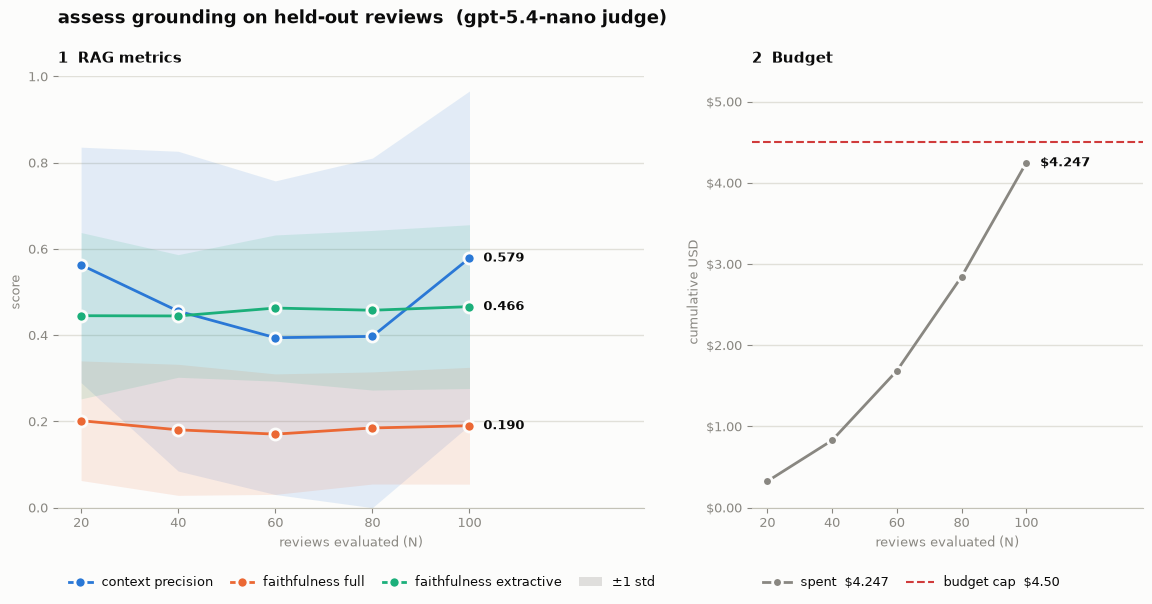

  n  llm_context_precision_without_reference  faithfulness_full  faithfulness_extractive  cost_usd  cumulative_usd  seconds
 20                                    0.563              0.202                    0.445     0.284           0.325  361.590
 40                                    0.456              0.181                    0.445     0.504           0.829  703.296
 60                                    0.394              0.171                    0.463     0.856           1.685 1030.666
 80                                    0.397              0.185                    0.458     1.159           2.844 1384.763
100                                    0.579              0.190                    0.466     1.403           4.247 2051.542


In [11]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# Two charts side by side rather than one chart with twin y-axes: scores are
# 0-1 and cost is USD, and a dual-axis plot lets the reader infer whatever
# relationship the rescaling implies. Separate charts keep the comparison honest.
#
# Palette: categorical slots 1-3 in fixed order, validated for CVD separation
# (worst adjacent pair dE 9.2 deutan). Slot 3 is below 3:1 on the surface, so
# every series is in the legend AND direct-labelled, and the table below
# repeats the numbers.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
SURFACE, CRITICAL = "#fcfcfb", "#d03b3b"

if sweep.empty:
    raise SystemExit("no completed sweep points -- nothing to plot. "
                     "Raise BUDGET_USD or use a cheaper generator.")

score_cols = [c for c in sweep.columns
              if c not in {"n", "seconds", "cost_usd", "cumulative_usd",
                           "n_extractive_count"}
              and not c.endswith("__std")]

# Friendlier names; ragas column names are long and version-dependent. The two
# faithfulness series keep their scope -- one label for both would merge them.
LABELS = {c: ("context precision" if "precision" in c or "utilization" in c
              else c.replace("_", " "))
          for c in score_cols}


def spread(values: list[float], gap: float) -> list[float]:
    """Label y-positions nudged apart so no two sit closer than `gap`.

    Scores that land close together (0.531 vs 0.543) otherwise print their
    direct labels on top of each other. Order is kept; only the labels move,
    never the points.
    """
    order = sorted(range(len(values)), key=lambda i: values[i])
    ys = list(values)
    for below, above in zip(order, order[1:]):
        ys[above] = max(ys[above], ys[below] + gap)
    return ys


fig, (ax_score, ax_cost) = plt.subplots(
    1, 2, figsize=(14, 5.6), sharex=True, width_ratios=[3, 2],
    gridspec_kw={"wspace": 0.22},
)
fig.patch.set_facecolor(SURFACE)
fig.suptitle(f"assess grounding on held-out reviews  ({JUDGE_MODEL} judge)",
             color=INK, fontsize=13, fontweight="bold", x=0.125, ha="left", y=1.0)

# Room on the right for the direct labels, which otherwise run off the chart.
span = max(sweep["n"].iloc[-1] - sweep["n"].iloc[0], 10)
ax_score.set_xlim(sweep["n"].iloc[0] - span * 0.06,
                  sweep["n"].iloc[-1] + span * 0.45)

# -- 1: RAG metrics vs N, with +/-1 std as a band -----------------------------
for colour, col in zip((BLUE, ORANGE, AQUA), score_cols):
    ax_score.plot(sweep["n"], sweep[col], color=colour, linewidth=2,
                  marker="o", markersize=8, markeredgecolor=SURFACE,
                  markeredgewidth=2, label=LABELS[col], zorder=3)

    std_col = f"{col}__std"
    if std_col in sweep:
        ax_score.fill_between(sweep["n"],
                              (sweep[col] - sweep[std_col]).clip(lower=0),
                              (sweep[col] + sweep[std_col]).clip(upper=1),
                              color=colour, alpha=0.12, linewidth=0, zorder=1)

# Zoom to the data with headroom rather than pinning 0-1: the whole question is
# whether the scores drift as N grows, and a 0-1 axis flattens that to a line.
# The +/-1 std band stays visible so the zoom cannot overstate a trend.
lo = min((sweep[c] - sweep.get(f"{c}__std", 0)).min() for c in score_cols)
hi = max((sweep[c] + sweep.get(f"{c}__std", 0)).max() for c in score_cols)
pad = max(0.05, (hi - lo) * 0.12)
ax_score.set_ylim(max(0, lo - pad), min(1.0, hi + pad))

# Direct-label the last point, nudged apart so close scores stay readable.
last = sweep.iloc[-1]
y_lo, y_hi = ax_score.get_ylim()
label_ys = spread([last[c] for c in score_cols], gap=(y_hi - y_lo) * 0.055)
for colour, col, y in zip((BLUE, ORANGE, AQUA), score_cols, label_ys):
    ax_score.annotate(f"{last[col]:.3f}", (last["n"], last[col]),
                      xytext=(10, y), textcoords=("offset points", "data"),
                      color=INK, fontsize=9.5, va="center", fontweight="bold",
                      annotation_clip=False)

ax_score.set_title("1  RAG metrics", color=INK, fontsize=11,
                   fontweight="bold", loc="left", pad=10)
ax_score.set_ylabel("score", color=MUTED, fontsize=9)
ax_score.set_xlabel("reviews evaluated (N)", color=MUTED, fontsize=9)

handles, _ = ax_score.get_legend_handles_labels()
# A band needs two points to have width -- at one point there is nothing to key.
if len(sweep) > 1 and any(f"{c}__std" in sweep for c in score_cols):
    handles.append(Patch(facecolor=MUTED, alpha=0.25, label="±1 std"))
ax_score.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.13),
                ncol=len(handles), frameon=False, fontsize=9,
                labelcolor=INK, handlelength=1.8, columnspacing=1.4)

# -- 2: cumulative spend against the cap --------------------------------------
ax_cost.plot(sweep["n"], sweep["cumulative_usd"], color=MUTED, linewidth=2,
             marker="o", markersize=7, markeredgecolor=SURFACE,
             markeredgewidth=2, zorder=3)
ax_cost.axhline(BUDGET_USD, color=CRITICAL, linewidth=1.5, linestyle="--", zorder=2)

spent = sweep["cumulative_usd"].iloc[-1]
ax_cost.annotate(f"${spent:.3f}", (sweep["n"].iloc[-1], spent),
                 xytext=(10, 0), textcoords="offset points", color=INK,
                 fontsize=9.5, va="center", fontweight="bold")

ax_cost.set_ylim(0, max(BUDGET_USD, spent) * 1.18)
ax_cost.set_title("2  Budget", color=INK, fontsize=11,
                  fontweight="bold", loc="left", pad=10)
ax_cost.set_ylabel("cumulative USD", color=MUTED, fontsize=9)
ax_cost.set_xlabel("reviews evaluated (N)", color=MUTED, fontsize=9)
ax_cost.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:.2f}"))

ax_cost.legend(
    handles=[
        Line2D([], [], color=MUTED, linewidth=2, marker="o", markersize=7,
               markeredgecolor=SURFACE, markeredgewidth=2,
               label=f"spent  ${spent:.3f}"),
        Line2D([], [], color=CRITICAL, linewidth=1.5, linestyle="--",
               label=f"budget cap  ${BUDGET_USD:.2f}"),
    ],
    loc="upper left", bbox_to_anchor=(0, -0.13), ncol=2, frameon=False,
    fontsize=9, labelcolor=INK, handlelength=2.2, columnspacing=1.4,
)

for ax in (ax_score, ax_cost):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.tick_params(axis="x", labelbottom=True)      # sharex hides nothing side by side
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.set_xticks(sweep["n"])

# Kept in `sweep_figure` so the run-record and MLflow cells can save it --
# plt.show() detaches the figure from pyplot's registry.
sweep_figure = fig
plt.show()

# The table view, so nothing depends on reading colour off a chart.
print(sweep[["n", *score_cols, "cost_usd", "cumulative_usd", "seconds"]]
      .to_string(index=False, float_format="{:.3f}".format))

### Before trusting a low score

ragas decomposes claims and judges relevance with **English** prompts, over
**Thai** review text. A bad faithfulness score may therefore mean the judge
failed on Thai — a finding about ragas, not about the pipeline.

So read the worst queries by hand before drawing a conclusion. The cell below
prints the lowest-scoring ones in full.

In [12]:
WORST_N = 3

# Inspect the largest completed sweep point -- it has the most queries and so
# the most chances to have caught a real failure.
if not sweep_frames:
    raise SystemExit("no completed sweep points -- nothing to inspect.")

largest = max(sweep_frames)
df = sweep_frames[largest]
cols = score_columns_of(df)
print(f"worst {WORST_N} of N={largest}\n")

# Rank by the weakest metric per row: a query that scored 0.9/0.2 is as much
# worth reading as one that scored 0.5/0.5. Ranked on a separate Series rather
# than an assigned column -- itertuples() mangles names starting with "_".
weakest = df[cols].min(axis=1)
worst = df.loc[weakest.nsmallest(WORST_N).index]

for position, row in enumerate(worst.itertuples(), 1):
    print("=" * 78)
    print(f"[{position}] " + "   ".join(
        f"{c}={getattr(row, c):.3f}" for c in cols))
    print(f"\nReview  {row.user_input}")
    print(f"\nA  {row.response}\n")

    for rank, context in enumerate(row.retrieved_contexts, 1):
        snippet = context.replace("\n", " ")[:200]
        print(f"  [{rank}] {snippet}")
    print()

# Judge it yourself: is the answer actually unsupported by those chunks, or did
# the judge simply not read Thai? Record the verdict in docs/phase_1/benchmark.md.

worst 3 of N=100

[1] llm_context_precision_without_reference=nan   faithfulness=0.000

Review  วันก่อนได้ชิมผัดซีอิ๊วรสเด็ดร้านราดหน้าคนแซ่แต้แล้วติดใจ วันนี้เลยไปที่สวนกล้วย Market อีกครั้ง ชอบนะ ที่จอดรถสะดวก ที่นั่งกินอาหารก็สะอาดใช้ได้ 

ระหว่างรอผัดซีอิ๊วและราดหน้าอยู่ มองไปเห็นในตู้ร้านก๋วยเตี๋ยวน้ำแดงสูตรเพชรบุรีมีไก่ทอดกับหมูทอดชิ้นใหญ่ดูน่ากิน เลยลองสั่งข้าวไก่ทอดมาลอง 1 จาน เค้าไม่แปะป้ายราคาไว้ แต่เดาว่าก็ราวๆ 35 - 40 แหละ

รอพักนึงแม่ค้ายกมาให้ที่โต๊ะ เอ่อ....ข้าวไก่ทอดจริงๆ ด้วย มีข้าวกับไก่ทอด ไม่มีผักเลย ไม่มีซุปด้วย 555 ยังดีมีน้ำจิ้มไก่มาให้ด้วย รสชาติพอกินได้ ฝืดคอทนหน่อย ปริมาณน้อยไปเมื่อเทียบกับราคา เนื้อไก่นิดเดียว จานนี้แม่ค้าเรียกเก็บ 40 บาท รู้งี้สั่งก๋วยเตี๋ยวอาจดีกว่า
 

A  1) Sentiment: negative; 0.75; จุดกระทบหลักคือปริมาณน้อยเมื่อเทียบกับราคา
2) Issues: - [taste] ฝืดคอทนหน่อย/รสชาติพอกินได้ - [portion] ปริมาณน้อยไปเมื่อเทียบกับราคา - [price] ราคากับปริมาณไม่คุ้ม
3) Precedent: taste (recurring; past_review 3) ; portion/value (recurring; past_review 2)
4) Ac

In [ ]:
1

In [13]:
# Spend ledger -- copy these into the run log in docs/phase_1/benchmark.md.
ledger = pd.DataFrame(budget.ledger)
print(ledger.to_string(index=False, float_format="{:.4f}".format))

print(f"\ntotal        ${budget.spent:.4f}  of ${budget.limit:.2f} cap")
print(f"             ~{budget.spent * 33.4:.2f} THB at 33.4 THB/USD")
print(f"remaining    ${budget.remaining:.4f}")
print(f"judge        {JUDGE_MODEL}   generator {settings.llm_model}")
print(f"run          {RUN_SLUG}")
print(f"sweep        N = {list(sweep['n'])}"
      + (f"  (stopped before {stopped_at})" if stopped_at else "  (complete)"))

# Judge rows are charged max(projected, actual): actual comes from ragas's
# OpenAI usage parser and includes reasoning tokens. Generation and embeddings
# are projected only -- app/ discards response.usage (C8). Reconcile those
# against the OpenAI usage dashboard before quoting them as measured.
for c in judge_cost:
    actual = f"${c['actual_usd']:.4f}" if c["actual_usd"] is not None else "not reported"
    print(f"judge {c['pass']:10} N={c['n']:3}  projected ${c['projected_usd']:.4f}  actual {actual}")
print("\nNote: generation is projected from token counts, not read back from OpenAI usage.")

                 label    usd  cumulative
            generation 0.0403      0.0403
     review embeddings 0.0009      0.0411
            judge N=20 0.1483      0.1895
 judge extractive N=20 0.1359      0.3254
            judge N=40 0.2557      0.5810
 judge extractive N=40 0.2480      0.8290
            judge N=60 0.4277      1.2567
 judge extractive N=60 0.4280      1.6847
            judge N=80 0.5867      2.2715
 judge extractive N=80 0.5727      2.8442
           judge N=100 0.7061      3.5503
judge extractive N=100 0.6966      4.2469

total        $4.2469  of $4.50 cap
             ~141.85 THB at 33.4 THB/USD
remaining    $0.2531
judge        gpt-5.4-nano   generator gpt-5-nano
run          assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358
sweep        N = [20, 40, 60, 80, 100]  (complete)
judge full       N= 20  projected $0.1483  actual $0.1002
judge extractive N= 20  projected $0.1359  actual $0.0308
judge full       N= 40  projected $0.2557  actual $0.1693
judge e

In [14]:
# ---- record the run ----
# Everything this run produced, in its own OUT_DIR (D9). dropped.json was
# written at the D4 count; responses.jsonl right after generation.
from collections import Counter

sweep.to_csv(OUT_DIR / "sweep.csv", index=False)

if "sweep_figure" in globals():
    sweep_figure.savefig(OUT_DIR / "sweep.png", dpi=150, facecolor=sweep_figure.get_facecolor())


def judge_stage(pass_name: str) -> dict:
    """Projected and actual judge spend for one pass, summed over points."""
    rows = [c for c in judge_cost if c["pass"] == pass_name]
    actuals = [c["actual_usd"] for c in rows]
    known = all(a is not None for a in actuals) and rows
    return {
        "projected_usd": sum(c["projected_usd"] for c in rows),
        "actual_usd": sum(actuals) if known else None,
        "actual_tokens": {
            "in": sum(c["actual_tokens"]["in"] or 0 for c in rows) if known else None,
            "out": sum(c["actual_tokens"]["out"] or 0 for c in rows) if known else None,
        },
        "actual_source": "ragas get_token_usage_for_openai "
                         "(completion tokens include reasoning)",
        "points": [c["n"] for c in rows],
    }


(OUT_DIR / "cost.json").write_text(json.dumps({
    "generation": {"projected_usd": generation_cost, "actual_usd": None,
                   "actual_source": "reconcile against the OpenAI usage dashboard (C8)"},
    "embeddings": {"projected_usd": embedding_cost, "actual_usd": None,
                   "actual_source": "reconcile against the OpenAI usage dashboard (C8)"},
    "judge_full": judge_stage("full"),
    "judge_extractive": judge_stage("extractive"),
    "budget_usd": BUDGET_USD,
    "charged_usd": budget.spent,
    "thb_per_usd": 33.4,
    "note": "projections count visible tokens only",
}, indent=2), encoding="utf-8")

(OUT_DIR / "run_meta.json").write_text(json.dumps({
    "run_slug": RUN_SLUG, "date_utc": TS, "git_sha": GIT_SHA,
    "judge_model": JUDGE_MODEL, "judge_model_status": "Deprecated per OpenAI model page, 2026-10-19",
    "judge_temperature": 1,
    "generator_model": settings.llm_model, "prompt_set": PROMPT_SET,
    "eval_set": EVAL_SET, "eval_file": str(EVAL_FILE), "eval_set_sha": EVAL_SET_SHA,
    "sample_seed": SAMPLE_SEED,
    "ragas_version": md.version("ragas"), "top_k": TOP_K,
    "n_max": N_MAX, "sweep_step": SWEEP_STEP, "completed_n": [int(n) for n in sweep["n"]] if not sweep.empty else [],
    "stopped_before_n": stopped_at,
    "n_extractive": len(records_extractive), "dropped_ids": [r["id"] for r in dropped],
    "self_retrieval_ids": [r["id"] for r in records if (r["top1_score"] or 0) >= 0.99],
    "max_top1_score": max((r["top1_score"] for r in records if r["top1_score"] is not None),
                          default=None),
    # Not stratification -- the source has no rating column (D5, Risk 17).
    "sentiment_mix": dict(Counter(sentiment_label(r["response"]) for r in records)),
    "resumed_from": globals().get("RESUMED_FROM"),
}, ensure_ascii=False, indent=2), encoding="utf-8")

for name in ("responses.jsonl", "dropped.json", "sweep.csv", "cost.json",
             "run_meta.json", "sweep.png"):
    path = OUT_DIR / name
    print(f"  {'ok' if path.exists() else '--'}  {path}")

  ok  data\eval\runs\assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358\responses.jsonl
  ok  data\eval\runs\assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358\dropped.json
  ok  data\eval\runs\assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358\sweep.csv
  ok  data\eval\runs\assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358\cost.json
  ok  data\eval\runs\assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358\run_meta.json
  ok  data\eval\runs\assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358\sweep.png


### Log the sweep to MLflow

Everything above lives in memory and dies with the kernel. This logs the sweep to
the tracking server at **`http://localhost:5000`** so the scores become a history
rather than one printout.

**Optional by design** — if `mlflow` is not installed or the server is
unreachable, the cell says so and moves on. Nothing above depends on it.

Shape: one **parent run** for the sweep, one **nested run per N**. Metrics are also
logged on the parent against `step=N`, so MLflow's own chart view plots
score-vs-N without any extra work, and the matplotlib figure is attached as an
artifact.

| Logged as | What |
|---|---|
| params | D10's set on the parent **and** every nested run (`prompt_set`, `eval_set`, `eval_set_sha`, `scoring_scope`, `judge_model`, `generator_model`, `run_slug`, `sample_seed`, `n_extractive`), plus ragas version, top_k, budget cap, collection |
| metrics | `context_precision`, `faithfulness_full`, `faithfulness_extractive` (+ std), cost, duration — per N. **Nothing is logged as plain `faithfulness`**: that key belongs to the old query-based run (D3) |
| artifacts | sweep table (CSV), per-query scores at the largest N (question + answer + **full untruncated contexts**), the chart |
| tags | whether the budget guard fired, embedding model, dataset size |

> **Why the params matter more than usual.** These are LLM-judged scores, so the
> judge model and the ragas version are *part of the measurement*, not metadata.
> A metric history that doesn't record them isn't comparable across runs — which
> is the whole reason for logging in the first place.

> **Cost is what the ledger charged**: the larger of projected and actual for the
> judge, projected for generation. It is logged as `cost_usd_charged`; actual judge
> spend is logged separately as `judge_*_actual_usd`.

MLflow also ships native RAGAS scorers (`mlflow.genai.scorers.ragas`), but those
re-judge through MLflow traces — which would pay for the judging a second time and
bypass the budget guard. The sweep already has the scores, so they are logged
directly.

Needs `pip install mlflow` and a server running:

```powershell
mlflow server --host 127.0.0.1 --port 5000
```

In [16]:
import importlib.metadata as md
import os
import sys

# MLflow 3 prints a "run finished" line containing an emoji when a run ends.
# On Windows the default console encoding is cp1252, which cannot encode it --
# that raises UnicodeEncodeError *after* the metrics are already logged, turning
# a successful run into a traceback. Force UTF-8 so the run closes cleanly.
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
    sys.stderr.reconfigure(encoding="utf-8", errors="replace")

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000")
MLFLOW_EXPERIMENT = "retail_rag/phase_1_ragas"

# Optional integration: a missing package or a down server must not invalidate
# an evaluation that has already been paid for. Both are treated as "skip and
# say so", never as an exception.
try:
    import mlflow
    mlflow_available = True
except ImportError:
    mlflow_available = False
    print("mlflow NOT INSTALLED  ->  pip install mlflow")
    print("Sweep results are still in `sweep` / `sweep_frames`; re-run this cell "
          "after installing to log them.")

if mlflow_available and sweep.empty:
    mlflow_available = False
    print("no completed sweep points -- nothing to log.")

if mlflow_available:
    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

    # Reachability is checked before opening a run, so a dead server does not
    # leave a half-written experiment behind.
    try:
        mlflow.set_experiment(MLFLOW_EXPERIMENT)
        print(f"mlflow {md.version('mlflow')}  ->  {MLFLOW_TRACKING_URI}")
        print(f"experiment: {MLFLOW_EXPERIMENT}")
    except Exception as exc:
        mlflow_available = False
        print(f"!! cannot reach {MLFLOW_TRACKING_URI}: {type(exc).__name__}")
        print("   start one with:  mlflow server --host 127.0.0.1 --port 5000")
        print("   results are still in `sweep` / `sweep_frames` -- re-run to log.")

mlflow 3.13.0  ->  http://localhost:5000
experiment: retail_rag/phase_1_ragas


In [17]:
if mlflow_available:
    # Friendly metric names, so the MLflow chart axes are readable. The ragas
    # column names are long and change across releases.
    def metric_name(col: str) -> str:
        if "precision" in col or "utilization" in col:
            return "context_precision"
        # faithfulness_full / faithfulness_extractive keep their names. Collapsing
        # them to "faithfulness" writes both series onto one key -- and onto the
        # old run's key -- which is exactly what D3/R5 forbid (C3).
        return col.replace("__", "_")

    # Joins the MLflow run to OUT_DIR (D10).
    run_name = RUN_SLUG

    # What would have to match for two runs to be comparable -- logged on the
    # parent AND every nested run, so a nested row is legible on its own (D10).
    D10_PARAMS = {
        "prompt_set": PROMPT_SET, "eval_set": EVAL_SET, "eval_set_sha": EVAL_SET_SHA,
        "scoring_scope": "full+extractive", "judge_model": JUDGE_MODEL,
        "generator_model": settings.llm_model, "run_slug": RUN_SLUG,
        "sample_seed": SAMPLE_SEED,
    }

    with mlflow.start_run(run_name=run_name) as parent:
        # -- params: what would have to match for two runs to be comparable ---
        mlflow.log_params(D10_PARAMS | {
            # The denominator is a param, never a metric (D10, Risk 6).
            "n_extractive": len(records_extractive),
            # gpt-5-* run at 1 whatever ragas asks for -- PinnedTempChatOpenAI.
            "judge_temperature": 1,
            "llm_provider": settings.llm_provider,
            "embedding_model": settings.embedding_model,
            "ragas_version": md.version("ragas"),
            "top_k": TOP_K,
            "metric_variant": "LLMContextPrecisionWithoutReference",
            "budget_cap_usd": BUDGET_USD,
            "generation_share": GENERATION_SHARE,
            "judge_passes_estimate": JUDGE_PASSES,
            "n_max": N_MAX,
            "sweep_step": SWEEP_STEP,
            "eval_file": str(EVAL_FILE),
            "answers_generated": len(records),
            "milvus_database": settings.milvus_database,
            "milvus_collection": settings.milvus_collection,
            "git_sha": GIT_SHA,
        })

        mlflow.set_tags({
            "phase": "1",
            "reference_free": "true",          # no ground-truth answers used
            "budget_guard_fired": str(bool(stopped_at)),
            "sweep_complete": str(stopped_at is None),
            "corpus_rows": 40000,
            "language": "th",
            "judge_model_status": "Deprecated per OpenAI model page, 2026-10-19",
        })

        # n_extractive_count is logged as the n_extractive PARAM above and in
        # each nested run -- never as a metric (D10).
        score_cols_mf = [c for c in sweep.columns
                         if c not in {"n", "seconds", "cost_usd", "cumulative_usd",
                                      "n_extractive_count"}
                         and not c.endswith("__std")]
        assert "faithfulness" not in {metric_name(c) for c in score_cols_mf}, \
            "a column would be logged as `faithfulness` -- D3/C3"

        # -- per-N metrics on the parent, stepped by N ------------------------
        # step=N is what makes MLflow's chart view plot score-vs-N directly.
        for row in sweep.itertuples():
            n = int(row.n)
            for col in score_cols_mf:
                value = getattr(row, col)
                if pd.isna(value):
                    continue
                mlflow.log_metric(metric_name(col), value, step=n)
                std_col = f"{col}__std"
                if std_col in sweep.columns and pd.notna(getattr(row, std_col)):
                    mlflow.log_metric(f"{metric_name(col)}_std",
                                      getattr(row, std_col), step=n)
            mlflow.log_metric("cost_usd_charged", row.cost_usd, step=n)
            mlflow.log_metric("cumulative_usd_charged", row.cumulative_usd, step=n)
            mlflow.log_metric("judge_seconds", row.seconds, step=n)

        # -- headline metrics: the largest N, unstepped so they sort in the UI -
        final = sweep.iloc[-1]
        for col in score_cols_mf:
            if pd.notna(final[col]):
                mlflow.log_metric(f"final_{metric_name(col)}", final[col])
        mlflow.log_metric("final_n", int(final["n"]))
        mlflow.log_metric("total_spent_usd_charged", budget.spent)
        mlflow.log_metric("budget_utilisation_pct", 100 * budget.spent / budget.limit)
        for c in judge_cost:
            if c["actual_usd"] is not None:
                mlflow.log_metric(f"judge_{c['pass']}_actual_usd", c["actual_usd"], step=c["n"])
            mlflow.log_metric(f"judge_{c['pass']}_projected_usd", c["projected_usd"], step=c["n"])

        # -- artifacts --------------------------------------------------------
        # Artifacts are the one part that can fail independently of the metrics.
        # This server's runs get an s3:// artifact_uri (--default-artifact-root
        # s3://mlflow/), so the *client* resolves the bucket directly and needs
        # boto3 + credentials -- having --serve-artifacts on the server is not
        # enough on its own. Params and metrics go over the tracking API and are
        # unaffected, so an artifact failure must never sink the whole run: the
        # scores are the paid-for result, the files are a convenience -- and they
        # are all in OUT_DIR regardless.
        #
        # To get artifacts working, either:
        #   (a) pip install boto3, and set in this notebook's environment:
        #         MLFLOW_S3_ENDPOINT_URL=http://localhost:9000
        #         AWS_ACCESS_KEY_ID / AWS_SECRET_ACCESS_KEY  (MinIO creds)
        #   (b) or restart the server with --artifacts-destination s3://mlflow/
        #       and --default-artifact-root mlflow-artifacts:/ so clients proxy
        #       through the tracking server and need no credentials at all.
        def try_artifact(label, fn):
            """Log one artifact, downgrading any failure to a warning."""
            try:
                fn()
                logged_artifacts.append(label)
            except Exception as exc:
                artifact_errors.append(f"{label}: {type(exc).__name__}")

        logged_artifacts, artifact_errors = [], []

        try_artifact("sweep.json",
                     lambda: mlflow.log_table(sweep, artifact_file="sweep.json"))

        # The run record from OUT_DIR, as written -- not a re-serialisation.
        for name in ("sweep.csv", "cost.json", "run_meta.json", "dropped.json"):
            if (OUT_DIR / name).exists():
                try_artifact(name, lambda p=OUT_DIR / name: mlflow.log_artifact(str(p)))

        # globals(), not dir(): dir() inside a cell body does not see
        # notebook-level names reliably.
        if "sweep_figure" in globals():
            try_artifact("score_vs_n.png",
                         lambda: mlflow.log_figure(globals()["sweep_figure"],
                                                   "score_vs_n.png"))
        else:
            print("note: run the chart cell first to log the figure")

        # Per-review scores at the largest N -- the level the mean hides.
        #
        # Contexts are stored in FULL, deliberately: this artifact is the only
        # durable record of what the LLM actually saw, so a truncated copy could
        # not be used to re-check a judge's verdict later. They are joined into
        # one string per row only because log_table needs a scalar per cell.
        CONTEXT_SEPARATOR = chr(10) * 2 + "--- chunk ---" + chr(10) * 2

        largest_n = max(sweep_frames)
        detail = sweep_frames[largest_n].copy()
        detail["n_contexts"] = detail["retrieved_contexts"].apply(len)
        detail["retrieved_contexts"] = detail["retrieved_contexts"].apply(
            CONTEXT_SEPARATOR.join)
        detail["context_chars"] = detail["retrieved_contexts"].str.len()

        print(f"  per-review artifact: {len(detail)} rows, "
              f"{detail['context_chars'].sum():,} context chars (untruncated)")
        try_artifact(f"per_query_N{largest_n}.json",
                     lambda: mlflow.log_table(
                         detail, artifact_file=f"per_query_N{largest_n}.json"))

        try_artifact("spend_ledger.json",
                     lambda: mlflow.log_table(pd.DataFrame(budget.ledger),
                                              artifact_file="spend_ledger.json"))

        # -- nested run per sweep point, so each N is filterable on its own ---
        for row in sweep.itertuples():
            n_x = getattr(row, "n_extractive_count", float("nan"))
            with mlflow.start_run(run_name=f"N={int(row.n)}", nested=True):
                mlflow.log_params(D10_PARAMS | {
                    "n_queries": int(row.n),
                    "n_extractive": int(n_x) if pd.notna(n_x) else 0,
                })
                for col in score_cols_mf:
                    if pd.notna(getattr(row, col)):
                        mlflow.log_metric(metric_name(col), getattr(row, col))
                mlflow.log_metric("cost_usd_charged", row.cost_usd)
                mlflow.log_metric("judge_seconds", row.seconds)

        parent_run_id = parent.info.run_id

    print(f"logged run {parent_run_id}  ({RUN_SLUG})")
    print(f"  {len(sweep)} nested runs (N = {list(sweep['n'])})")
    print("  metrics + params: OK (tracking API)")

    if logged_artifacts:
        print(f"  artifacts: {', '.join(logged_artifacts)}")
    if artifact_errors:
        print(f"  !! artifacts NOT logged: {'; '.join(artifact_errors)}")
        print("     metrics and params are unaffected -- see the comment above")
        print("     for the two ways to fix artifact storage. OUT_DIR has every file.")

    experiment_id = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT).experiment_id
    print(f"  view: {MLFLOW_TRACKING_URI}/#/experiments/{experiment_id}"
          f"/runs/{parent_run_id}")

  per-review artifact: 100 rows, 535,783 context chars (untruncated)
🏃 View run N=20 at: http://localhost:5000/#/experiments/4/runs/63a33c337da34f0da41858f7b6eb2981
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run N=40 at: http://localhost:5000/#/experiments/4/runs/b45fc4ee5ca042e2b98bf04f7d4de9ae
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run N=60 at: http://localhost:5000/#/experiments/4/runs/577c99cb775146119811da1a7054646b
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run N=80 at: http://localhost:5000/#/experiments/4/runs/b4b733edaaca4a17b56b081294d25cd9
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run N=100 at: http://localhost:5000/#/experiments/4/runs/36c97e64b4e74ce3babaa7d6cb2d63e5
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run assess-reviews_heldout-N100-step20-gpt-5.4-nano-20261027-0358 at: http://localhost:5000/#/experiments/4/runs/d2bf6176f70c4e71be8fed908b974b